## Imports and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("country-averages-data.csv")   
df.head()

,COUNTRY_CODE,COUNTRY_NAME,TRUST_SCORE,WEIGHT_CNTRY,DEM_GENDER,DEM_GENDER_male,DEM_AGE,DEM_AGEGRP,DEM_EDU_uni
0,ALB,Albania,3.583333,0.025629,1,1,26,18-29,1
1,ALB,Albania,1.250000,2.078925,1,1,37,30-39,0
2,ALB,Albania,3.416667,1.699914,0,0,51,50-59,1
3,ALB,Albania,2.583333,0.045004,1,1,30,30-39,1
4,ALB,Albania,2.666667,10.100950,0,0,31,30-39,0


## Data quality check

In [5]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
print("Number of countries:", df["COUNTRY_NAME"].nunique())
print("Is DEM_GENDER identical to DEM_GENDER_male?", (df["DEM_GENDER"] == df["DEM_GENDER_male"]).all())

df.describe()

Shape: (69534, 9)

Missing values:
 COUNTRY_CODE       0
COUNTRY_NAME       0
TRUST_SCORE        7
WEIGHT_CNTRY       0
DEM_GENDER         0
DEM_GENDER_male    0
DEM_AGE            0
DEM_AGEGRP         0
DEM_EDU_uni        0
dtype: int64

Duplicated rows: 12830
Number of countries: 68
Is DEM_GENDER identical to DEM_GENDER_male? True


,TRUST_SCORE,WEIGHT_CNTRY,DEM_GENDER,DEM_GENDER_male,DEM_AGE,DEM_EDU_uni
count,69527.000000,69534.000000,69534.000000,69534.000000,69534.000000,69534.000000
mean,3.631292,1.000149,0.502488,0.502488,43.680171,0.592444
std,0.695955,1.228788,0.499997,0.499997,15.079127,0.491383
min,1.000000,0.019010,0.000000,0.000000,18.000000,0.000000
25%,3.166667,0.425227,0.000000,0.000000,31.000000,0.000000
50%,3.666667,0.686907,1.000000,1.000000,43.000000,1.000000
75%,4.083333,1.177922,1.000000,1.000000,55.000000,1.000000
max,5.000000,78.526504,1.000000,1.000000,93.000000,1.000000


In [22]:
df = df.dropna(subset=["TRUST_SCORE"]).copy()

## Sample size per country and weight overview

In [23]:
print(df["COUNTRY_NAME"].value_counts().describe())
print()
print(df["WEIGHT_CNTRY"].describe())
print("Non-positive weights:", (df["WEIGHT_CNTRY"] <= 0).sum())

count      68.000000
mean     1022.455882
std      1102.744939
min       312.000000
25%       493.000000
50%       507.500000
75%      1077.250000
max      8011.000000
Name: count, dtype: float64

count    69527.000000
mean         1.000116
std          1.228831
min          0.019010
25%          0.425227
50%          0.686907
75%          1.177922
max         78.526504
Name: WEIGHT_CNTRY, dtype: float64
Non-positive weights: 0


## Step 3, weighted vs. unweighted means per country

In [24]:
def summarize(g):
    w = g["WEIGHT_CNTRY"]
    x = g["TRUST_SCORE"]
    return pd.Series({
        "n": len(g),
        "unweighted": x.mean(),
        "weighted": np.average(x, weights=w),
        "n_eff": w.sum() ** 2 / (w ** 2).sum(),      # Kish effective sample size
        "w_max_min_ratio": w.max() / w.min(),
        "w_p99_median_ratio": w.quantile(0.99) / w.median(),
    })

res = df.groupby("COUNTRY_NAME").apply(summarize, include_groups=False)
res["diff"] = res["weighted"] - res["unweighted"]
res["abs_diff"] = res["diff"].abs()
res["n_eff_share"] = res["n_eff"] / res["n"]

res.sort_values("abs_diff", ascending=False).round(3).head(10)

,n,unweighted,weighted,n_eff,w_max_min_ratio,w_p99_median_ratio,diff,abs_diff,n_eff_share
COUNTRY_NAME,,,,,,,,,
Ethiopia,363.0,3.519,3.234,29.119,1150.111,206.861,-0.285,0.285,0.080
Egypt,420.0,4.139,4.295,52.877,638.383,62.968,0.156,0.156,0.126
Uganda,387.0,3.677,3.815,50.853,566.293,180.481,0.138,0.138,0.131
Albania,343.0,3.178,3.055,14.262,3063.992,129.790,-0.123,0.123,0.042
Morocco,375.0,3.562,3.684,99.979,163.838,33.623,0.122,0.122,0.267
Uruguay,312.0,3.620,3.510,103.663,77.007,14.471,-0.110,0.110,0.332
Ghana,474.0,3.879,3.771,51.607,1136.674,223.466,-0.108,0.108,0.109
Botswana,401.0,3.667,3.773,55.723,288.658,80.693,0.105,0.105,0.139
Côte d'Ivoire,466.0,3.500,3.595,68.771,575.586,235.536,0.095,0.095,0.148


## Summary of the weighting effect

In [25]:
print(res[["diff", "abs_diff", "n_eff_share"]].describe().round(3))
print("\nCountries where weighting increases trust:", (res["diff"] > 0).sum())
print("Countries where weighting decreases trust:", (res["diff"] < 0).sum())
print("\nLargest differences (signed):")
print(res["diff"].sort_values().round(3).iloc[[0, 1, 2, -3, -2, -1]])

         diff  abs_diff  n_eff_share
count  68.000    68.000       68.000
mean   -0.007     0.038        0.502
std     0.061     0.048        0.269
min    -0.285     0.000        0.042
25%    -0.026     0.009        0.303
50%    -0.004     0.024        0.524
75%     0.011     0.043        0.724
max     0.156     0.285        0.979

Countries where weighting increases trust: 30
Countries where weighting decreases trust: 38

Largest differences (signed):
COUNTRY_NAME
Ethiopia   -0.285
Albania    -0.123
Uruguay    -0.110
Morocco     0.122
Uganda      0.138
Egypt       0.156
Name: diff, dtype: float64


## Step 4, dumbbell plot (unweighted vs. weighted)

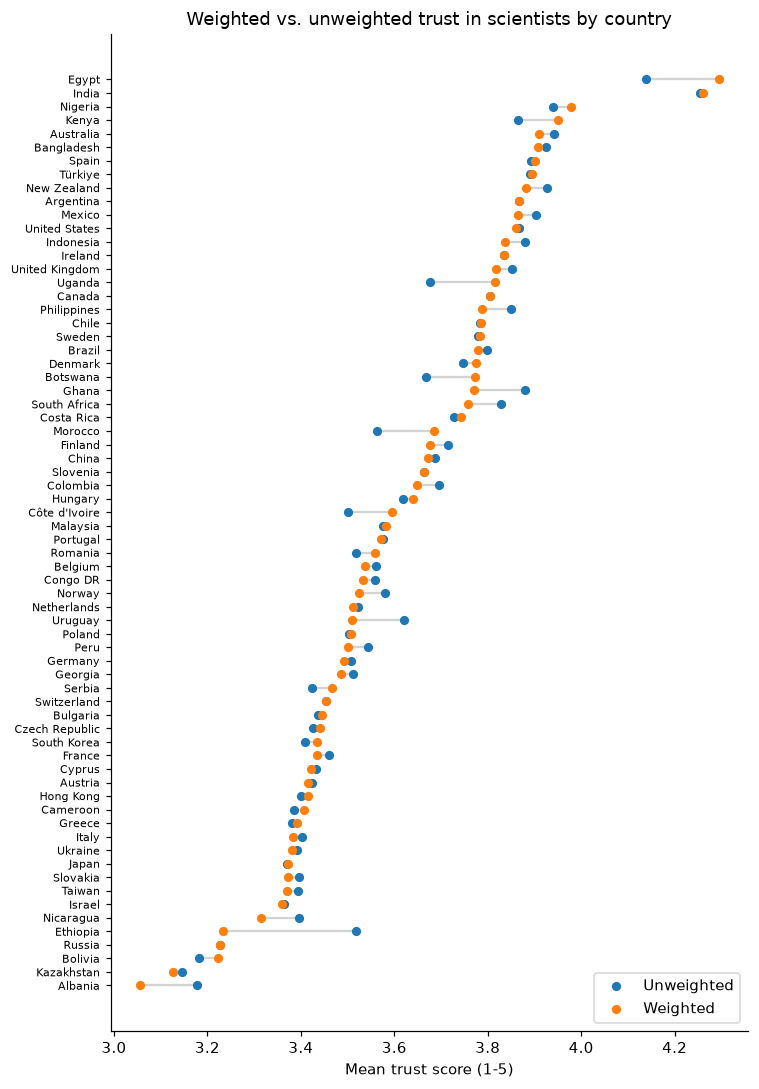

In [26]:
plot_df = res.sort_values("weighted")
y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(7, 10))
ax.hlines(y, plot_df["unweighted"], plot_df["weighted"], color="lightgrey", zorder=1)
ax.scatter(plot_df["unweighted"], y, color="tab:blue", label="Unweighted", zorder=2, s=25)
ax.scatter(plot_df["weighted"], y, color="tab:orange", label="Weighted", zorder=2, s=25)
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index, fontsize=7)
ax.set_xlabel("Mean trust score (1-5)")
ax.set_title("Weighted vs. unweighted trust in scientists by country")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig1_dumbbell.png", dpi=200)
plt.show()

## Does weighting affect all countries equally?

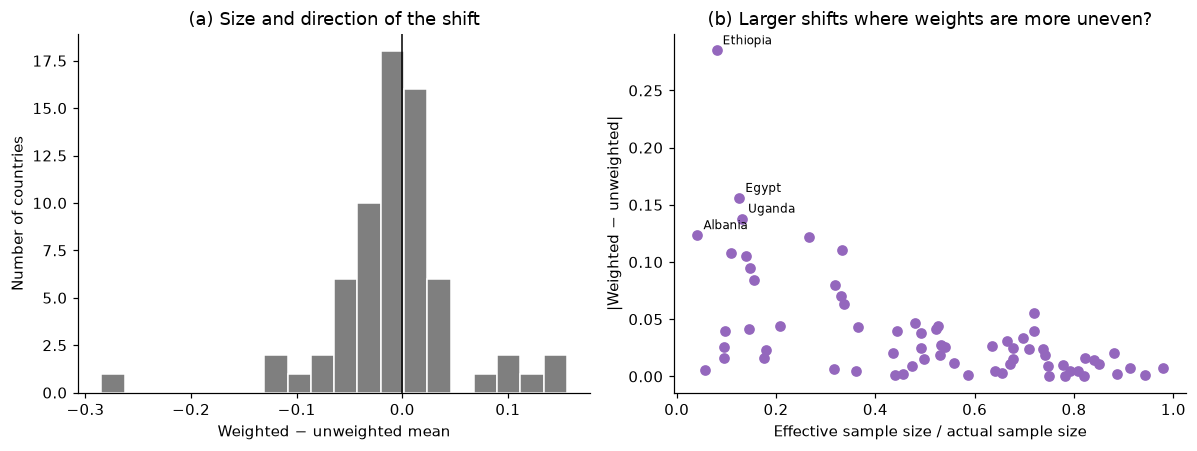

Correlation (|diff| vs. n_eff_share): -0.581


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) distribution of differences
axes[0].hist(res["diff"], bins=20, color="tab:grey", edgecolor="white")
axes[0].axvline(0, color="black", lw=1)
axes[0].set_xlabel("Weighted − unweighted mean")
axes[0].set_ylabel("Number of countries")
axes[0].set_title("(a) Size and direction of the shift")

# (b) shift vs. efficiency of the weights
axes[1].scatter(res["n_eff_share"], res["abs_diff"], color="tab:purple")
for name in res.sort_values("abs_diff", ascending=False).index[:4]:
    axes[1].annotate(name, (res.loc[name, "n_eff_share"], res.loc[name, "abs_diff"]),
                     fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("Effective sample size / actual sample size")
axes[1].set_ylabel("|Weighted − unweighted|")
axes[1].set_title("(b) Larger shifts where weights are more uneven?")

plt.tight_layout()
plt.savefig("fig2_patterns.png", dpi=200)
plt.show()

print("Correlation (|diff| vs. n_eff_share):",
      round(res["abs_diff"].corr(res["n_eff_share"]), 3))

## Step 5, country with the largest difference

In [28]:
top = res["abs_diff"].idxmax()
print("Country with the largest difference:", top)
print(res.loc[top].round(3))

sub = df[df["COUNTRY_NAME"] == top].copy()

Country with the largest difference: Ethiopia
n                      363.000
unweighted               3.519
weighted                 3.234
n_eff                   29.119
w_max_min_ratio       1150.111
w_p99_median_ratio     206.861
diff                    -0.285
abs_diff                 0.285
n_eff_share              0.080
Name: Ethiopia, dtype: float64


## High-weight vs. low-weight participants

In [29]:
# Median split by rank (robust to many identical weights)
sub["weight_group"] = np.where(
    sub["WEIGHT_CNTRY"].rank(method="first") <= len(sub) / 2, "low weight", "high weight"
)

comp = sub.groupby("weight_group").agg(
    n=("TRUST_SCORE", "size"),
    mean_weight=("WEIGHT_CNTRY", "mean"),
    age_mean=("DEM_AGE", "mean"),
    share_male=("DEM_GENDER_male", "mean"),
    share_uni=("DEM_EDU_uni", "mean"),
    mean_trust=("TRUST_SCORE", "mean"),
).round(3)
comp

,n,mean_weight,age_mean,share_male,share_uni,mean_trust
weight_group,,,,,,
high weight,182,1.960,32.593,0.703,0.654,3.489
low weight,181,0.035,26.116,0.464,1.000,3.548


In [30]:
age_dist = (sub.groupby("weight_group")["DEM_AGEGRP"]
              .value_counts(normalize=True).unstack().round(3))
age_dist

DEM_AGEGRP,18-29,30-39,40-49,50-59
weight_group,,,,
high weight,0.28,0.527,0.126,0.066
low weight,0.84,0.160,NaN,NaN


## Sample composition before vs. after weighting

In [31]:
def share(col, weights=None):
    if weights is None:
        return sub[col].value_counts(normalize=True)
    return sub.groupby(col)["WEIGHT_CNTRY"].sum() / sub["WEIGHT_CNTRY"].sum()

rows = []
for col in ["DEM_AGEGRP", "DEM_GENDER_male", "DEM_EDU_uni"]:
    u, w = share(col), share(col, weights=True)
    t = pd.DataFrame({"variable": col, "category": u.index,
                      "unweighted_share": u.values, "weighted_share": w.reindex(u.index).values})
    rows.append(t)

composition = pd.concat(rows, ignore_index=True)
composition["change"] = composition["weighted_share"] - composition["unweighted_share"]
composition.round(3)

,variable,category,unweighted_share,weighted_share,change
0,DEM_AGEGRP,18-29,0.559,0.425,-0.134
1,DEM_AGEGRP,30-39,0.344,0.233,-0.111
2,DEM_AGEGRP,40-49,0.063,0.254,0.190
3,DEM_AGEGRP,50-59,0.033,0.088,0.055
4,DEM_GENDER_male,1,0.584,0.503,-0.081
5,DEM_GENDER_male,0,0.416,0.497,0.081
6,DEM_EDU_uni,1,0.826,0.059,-0.767
7,DEM_EDU_uni,0,0.174,0.941,0.767


## Figure for the case study

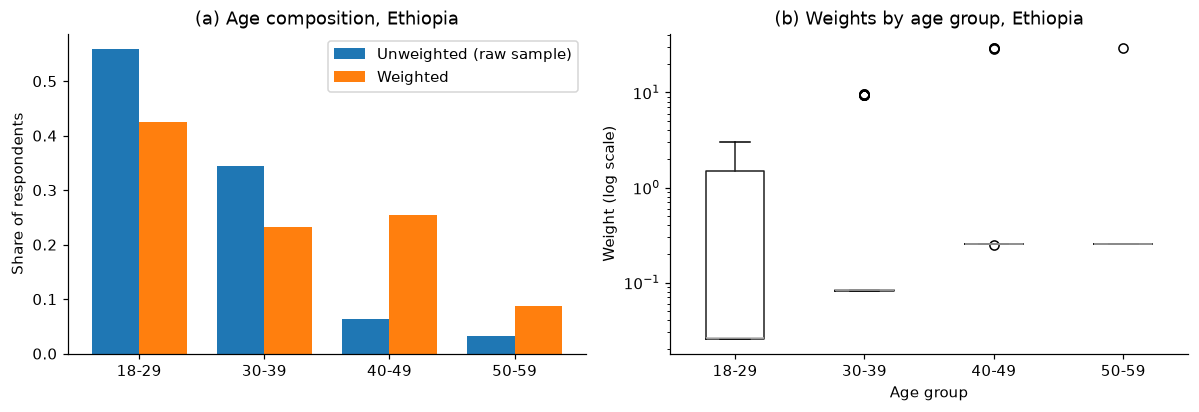

In [32]:
age_order = sorted(sub["DEM_AGEGRP"].unique())
u = share("DEM_AGEGRP").reindex(age_order)
w = share("DEM_AGEGRP", weights=True).reindex(age_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x = np.arange(len(age_order)); bw = 0.38
axes[0].bar(x - bw/2, u.values, bw, label="Unweighted (raw sample)", color="tab:blue")
axes[0].bar(x + bw/2, w.values, bw, label="Weighted", color="tab:orange")
axes[0].set_xticks(x); axes[0].set_xticklabels(age_order)
axes[0].set_ylabel("Share of respondents")
axes[0].set_title(f"(a) Age composition, {top}")
axes[0].legend()

sub.boxplot(column="WEIGHT_CNTRY", by="DEM_AGEGRP", ax=axes[1], grid=False)
axes[1].set_yscale("log")
axes[1].set_xlabel("Age group"); axes[1].set_ylabel("Weight (log scale)")
axes[1].set_title(f"(b) Weights by age group, {top}")
plt.suptitle("")

plt.tight_layout()
plt.savefig("fig3_case_study.png", dpi=200)
plt.show()

## Does trust differ across the groups the weights adjust?

In [33]:
for col in ["DEM_AGEGRP", "DEM_GENDER_male", "DEM_EDU_uni"]:
    print(sub.groupby(col)["TRUST_SCORE"].agg(["mean", "count"]).round(3), "\n")

             mean  count
DEM_AGEGRP              
18-29       3.560    203
30-39       3.461    125
40-49       3.551     23
50-59       3.361     12 

                  mean  count
DEM_GENDER_male              
0                3.454    151
1                3.565    212 

              mean  count
DEM_EDU_uni              
0            3.361     63
1            3.552    300 



## Step 6, how stable is the weighted estimate? (trimming and bootstrap)

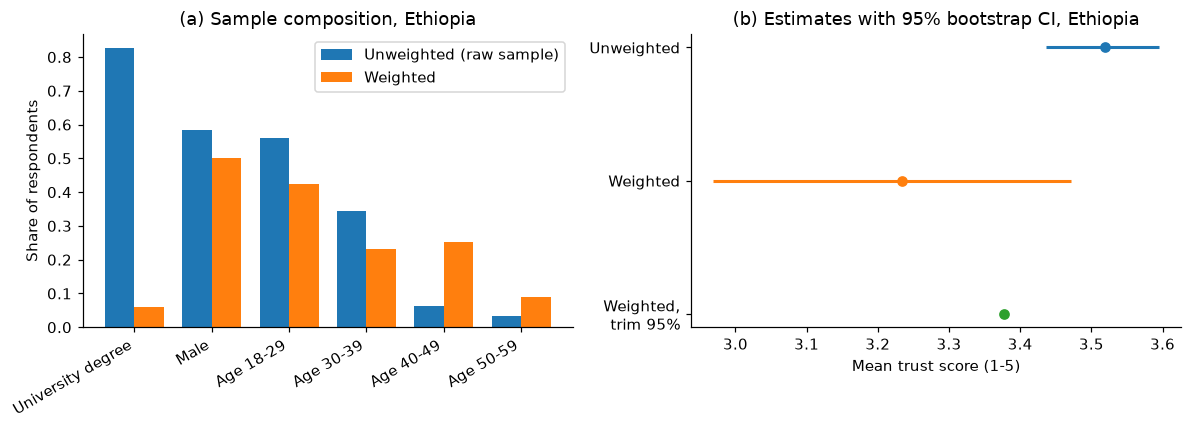

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cats = [("DEM_EDU_uni", 1, "University degree"), ("DEM_GENDER_male", 1, "Male"),
        ("DEM_AGEGRP", "18-29", "Age 18-29"), ("DEM_AGEGRP", "30-39", "Age 30-39"),
        ("DEM_AGEGRP", "40-49", "Age 40-49"), ("DEM_AGEGRP", "50-59", "Age 50-59")]
u = [share(c).get(v, 0) for c, v, _ in cats]
w = [share(c, weights=True).get(v, 0) for c, v, _ in cats]
x = np.arange(len(cats)); bw = 0.38
axes[0].bar(x - bw/2, u, bw, label="Unweighted (raw sample)", color="tab:blue")
axes[0].bar(x + bw/2, w, bw, label="Weighted", color="tab:orange")
axes[0].set_xticks(x); axes[0].set_xticklabels([l for _, _, l in cats], rotation=30, ha="right")
axes[0].set_ylabel("Share of respondents")
axes[0].set_title(f"(a) Sample composition, {top}")
axes[0].legend()

# (b) estimates and uncertainty
est = {"Unweighted": (sub["TRUST_SCORE"].mean(), ci(boot_u)),
       "Weighted": (np.average(sub["TRUST_SCORE"], weights=sub["WEIGHT_CNTRY"]), ci(boot_w)),
       "Weighted,\ntrim 95%": (trimmed_mean(sub, 0.95), None)}
for i, (k, (m, c)) in enumerate(est.items()):
    col = ["tab:blue", "tab:orange", "tab:green"][i]
    axes[1].scatter(m, i, color=col, zorder=3)
    if c is not None:
        axes[1].hlines(i, c[0], c[1], color=col, lw=2)
axes[1].set_yticks(range(len(est))); axes[1].set_yticklabels(est.keys())
axes[1].invert_yaxis()
axes[1].set_xlabel("Mean trust score (1-5)")
axes[1].set_title(f"(b) Estimates with 95% bootstrap CI, {top}")

plt.tight_layout()
plt.savefig("fig3_case_study.png", dpi=200)
plt.show()

In [38]:
# (a) Trim extreme weights at the 95th / 99th percentile
def trimmed_mean(g, q):
    w = g["WEIGHT_CNTRY"].clip(upper=g["WEIGHT_CNTRY"].quantile(q))
    return np.average(g["TRUST_SCORE"], weights=w)

print(f"{top}:")
print("  Unweighted:         ", round(sub["TRUST_SCORE"].mean(), 3))
print("  Weighted:           ", round(np.average(sub["TRUST_SCORE"], weights=sub["WEIGHT_CNTRY"]), 3))
print("  Weighted, trim 99%: ", round(trimmed_mean(sub, 0.99), 3))
print("  Weighted, trim 95%: ", round(trimmed_mean(sub, 0.95), 3))

# (b) Bootstrap 95% CI, unweighted vs. weighted
rng = np.random.default_rng(42)
B = 2000
x, w = sub["TRUST_SCORE"].to_numpy(), sub["WEIGHT_CNTRY"].to_numpy()
idx = rng.integers(0, len(sub), size=(B, len(sub)))
boot_u = x[idx].mean(axis=1)
boot_w = (x[idx] * w[idx]).sum(axis=1) / w[idx].sum(axis=1)

ci = lambda a: np.percentile(a, [2.5, 97.5]).round(3)
print("\nBootstrap 95% CI, unweighted:", ci(boot_u))
print("Bootstrap 95% CI, weighted:  ", ci(boot_w))

Ethiopia:
  Unweighted:          3.519
  Weighted:            3.234
  Weighted, trim 99%:  3.226
  Weighted, trim 95%:  3.377

Bootstrap 95% CI, unweighted: [3.436 3.595]
Bootstrap 95% CI, weighted:   [2.969 3.471]


## Uncertainty across all countries

In [39]:
def boot_ci_width(g, B=500, seed=0):
    rng = np.random.default_rng(seed)
    x, w = g["TRUST_SCORE"].to_numpy(), g["WEIGHT_CNTRY"].to_numpy()
    idx = rng.integers(0, len(g), size=(B, len(g)))
    bu = x[idx].mean(axis=1)
    bw = (x[idx] * w[idx]).sum(axis=1) / w[idx].sum(axis=1)
    return pd.Series({"ci_width_unweighted": np.subtract(*np.percentile(bu, [97.5, 2.5])),
                      "ci_width_weighted": np.subtract(*np.percentile(bw, [97.5, 2.5]))})

ci_res = df.groupby("COUNTRY_NAME").apply(boot_ci_width, include_groups=False)
ci_res["ratio"] = ci_res["ci_width_weighted"] / ci_res["ci_width_unweighted"]

print("Median CI width ratio (weighted / unweighted):", round(ci_res["ratio"].median(), 2))
print("Countries where weighting widens the CI:", (ci_res["ratio"] > 1).sum(), "of", len(ci_res))
ci_res.sort_values("ratio", ascending=False).round(3).head(8)

Median CI width ratio (weighted / unweighted): 1.4
Countries where weighting widens the CI: 68 of 68


,ci_width_unweighted,ci_width_weighted,ratio
COUNTRY_NAME,,,
India,0.108,0.463,4.299
China,0.135,0.476,3.531
Congo DR,0.139,0.457,3.287
Uganda,0.152,0.474,3.121
Ethiopia,0.152,0.463,3.039
Ghana,0.118,0.315,2.668
Nigeria,0.086,0.216,2.530
Côte d'Ivoire,0.118,0.296,2.514


## Summary numbers for the report

In [40]:
print("Countries:", len(res))
print("Mean |diff|:", round(res["abs_diff"].mean(), 3), "| Max |diff|:", round(res["abs_diff"].max(), 3), f"({top})")
print("Share of countries with |diff| < 0.05:", round((res["abs_diff"] < 0.05).mean(), 2))
print("Median n_eff / n:", round(res["n_eff_share"].median(), 2),
      "| Min:", round(res["n_eff_share"].min(), 2), f"({res['n_eff_share'].idxmin()})")
print("Largest weight ratio (max/min):", int(res["w_max_min_ratio"].max()), f"({res['w_max_min_ratio'].idxmax()})")

Countries: 68
Mean |diff|: 0.038 | Max |diff|: 0.285 (Ethiopia)
Share of countries with |diff| < 0.05: 0.79
Median n_eff / n: 0.52 | Min: 0.04 (Albania)
Largest weight ratio (max/min): 3063 (Albania)
